In [17]:
#Importing relevant libraries
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
from rdkit.Chem import PandasTools

import pandas as pd
import numpy as np

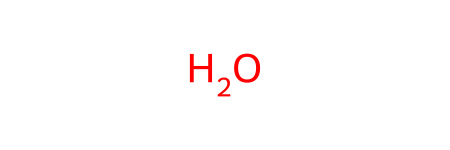

In [3]:
water = Chem.MolFromSmiles('O')
water

In [7]:
#Loading the dataset
url = "https://raw.githubusercontent.com/Natashasia/CHE1147-Group-6/main/raw_data_tox21.csv"
df = pd.read_csv(url)

#Checking the dataset
df.head()

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


In [12]:
#Checking for any duplicate molecules in the dataset
unique_smiles = df['smiles'].nunique()
num_smiles = df['smiles'].shape[0]
print(f'Unique SMILES: {unique_smiles}')
print(f'Total SMILES: {num_smiles}')

Unique SMILES: 7831
Total SMILES: 7831


In [14]:
#Declare a function for canonicalizing isomeric SMILES
def con_smiles(smile, isomeric:bool=True):
    mol = Chem.MolFromSmiles(smile)
    canonical_smiles = Chem.MolToSmiles(mol, isomericSmiles=isomeric)
    return canonical_smiles

In [18]:
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='smiles', molCol = 'molecule')
df.head()

[10:26:11] WARNING: not removing hydrogen atom without neighbors
[10:26:11] Explicit valence for atom # 8 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 3 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 4 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 4 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 9 Al, 6, is greater than permitted
[10:26:11] Explicit valence for atom # 5 Al, 6, is greater than permitted
[10:26:12] Explicit valence for atom # 16 Al, 6, is greater than permitted
[10:26:12] Explicit valence for atom # 20 Al, 6, is greater than permitted


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles,molecule
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,<rdkit.Chem.rdchem.Mol object at 0x00000200A4B...


In [ ]:
def calculate_key_descriptors(mol):
    descriptors = {
        'MolWt': Descriptors.MolWt(mol),
        'LogP' : Descriptors.MolLogP(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'RotBonds' : Descriptors.NumRotatableBonds(mol)
    }
    return descriptors

descriptor_data = []
for row, mol in df['molecule'].items():
    if mol is None:
        desc = {
            'MolWt': np.nan,
            'LogP': np.nan,
            'TPSA': np.nan,
            'NumHDonors': np.nan,
            'NumHAcceptors': np.nan,
            'RotBonds': np.nan
        }
    else:
        desc = calculate_key_descriptors(mol)
    descriptor_data.append(desc)

descriptor_df = pd.DataFrame(descriptor_data, index=df.index)

df_with_descriptors = pd.concat([df, descriptor_df], axis=1)

df_with_descriptors.head()

ArgumentError: Python argument types in
    rdkit.Chem.rdMolDescriptors._CalcMolWt(NoneType)
did not match C++ signature:
    _CalcMolWt(class RDKit::ROMol mol, bool onlyHeavy=False)